In [1]:
! pip install opencv-python

In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [36]:
df_owid = pd.read_csv("Dataset2.csv")
print(df_owid.columns)

Index(['Entity', 'Code', 'Year',
       'Period life expectancy at birth - Sex: total - Age: 0'],
      dtype='object')


In [38]:
# Load dataset
df_owid = pd.read_csv("Dataset2.csv")
df_kaggle = pd.read_csv("Life Expectancy Data.csv")
# Rename columns for easier use
df_owid = df_owid.rename(columns={
    "Entity": "Country",
    "Period life expectancy at birth - Sex: total - Age: 0": "Life_Expectancy"
})

# Drop rows with missing life expectancy values
df_owid = df_owid.dropna(subset=["Life_Expectancy"])

# Convert Year to integer (if needed)
df_owid["Year"] = df_owid["Year"].astype(int)

# Remove rows where 'Code' is missing (optional)
df_owid = df_owid[df_owid["Code"].notna()]

print(df_owid.head())

       Country Code  Year  Life_Expectancy
0  Afghanistan  AFG  1950          28.1563
1  Afghanistan  AFG  1951          28.5836
2  Afghanistan  AFG  1952          29.0138
3  Afghanistan  AFG  1953          29.4521
4  Afghanistan  AFG  1954          29.6975


In [40]:
# 1. Perform the merge WITH indicator
merged_df = pd.merge(
    df_kaggle,
    df_owid,
    on=['Country', 'Year'],
    how='left',
    indicator=True  # Creates the '_merge' column
)
# 2. Clean column names by stripping whitespace
merged_df.columns = merged_df.columns.str.strip()
    
# Count merge statuses
merge_stats = merged_df['_merge'].value_counts()
print("Merge Results:")
print(merge_stats)
    
# Calculate match rate with safety checks
total_kaggle = len(df_kaggle)
matched = merge_stats.get('both', 0)
match_rate = (matched / total_kaggle) * 100 if total_kaggle > 0 else 0
    
print("\nDebugging info:")
print(f"Kaggle columns: {df_kaggle.columns.tolist()}")
print(f"OWID columns: {df_owid.columns.tolist()}")
print(f"Merged columns: {merged_df.columns.tolist()}")

Merge Results:
_merge
both          2602
left_only      336
right_only       0
Name: count, dtype: int64

Debugging info:
Kaggle columns: ['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years', ' thinness 5-9 years', 'Income composition of resources', 'Schooling']
OWID columns: ['Country', 'Code', 'Year', 'Life_Expectancy']
Merged columns: ['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Code', 'Life_Expectancy', '_merge']


In [48]:
print(f"Kaggle columns: {df_kaggle.columns.tolist()}")
print(f"OWID columns: {df_owid.columns.tolist()}")
print(f"Merged columns: {merged_df.columns.tolist()}")

Kaggle columns: ['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years', ' thinness 5-9 years', 'Income composition of resources', 'Schooling']
OWID columns: ['Country', 'Code', 'Year', 'Life_Expectancy']
Merged columns: ['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling', 'Code', 'Life_Expectancy']
['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', '

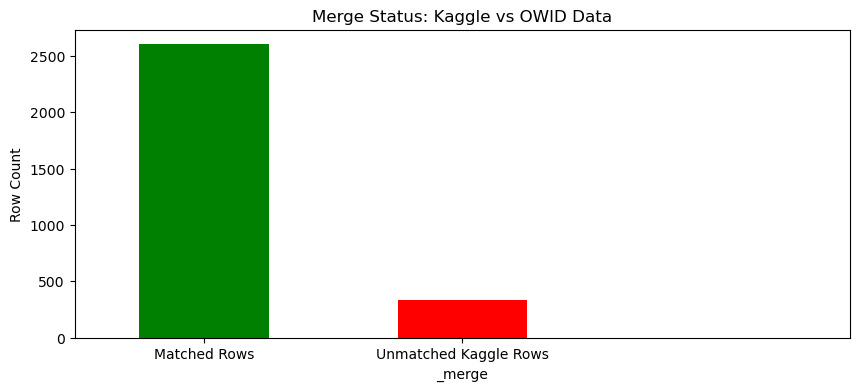

In [61]:
#data visualization for the number of rows that are matched between the 2 datasets and the number of rows that are unmatched
plt.figure(figsize=(10, 4))
merge_stats.plot(kind='bar', color=['green', 'red'])
plt.title('Merge Status: Kaggle vs OWID Data')
plt.ylabel('Row Count')
plt.xticks([0, 1], ['Matched Rows', 'Unmatched Kaggle Rows'], rotation=0)
plt.show()

<Figure size 1000x800 with 0 Axes>

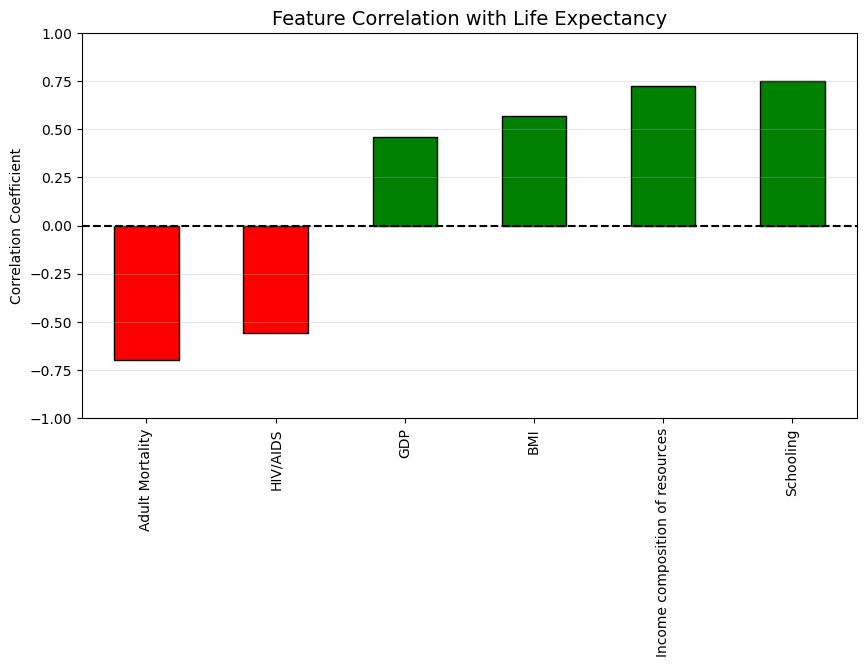

In [69]:
# visualizes the correlations between life expectancy and other key health/economic factors in your dataset

# Select relevant numerical features
corr_features = [
    'Life expectancy ',
    'GDP',
    'Schooling',
    ' BMI ',
    'Adult Mortality',
    'Income composition of resources',
    ' HIV/AIDS'
]

# Clean column names by stripping whitespace
merged_df.columns = merged_df.columns.str.strip()

# Recompute with cleaned names
corr_matrix = merged_df[[
    'Life expectancy',
    'GDP',
    'Schooling',
    'BMI',
    'Adult Mortality',
    'Income composition of resources',
    'HIV/AIDS'
]].corr() # pandas corr() method computes Pearson correlations

# Visualization
plt.figure(figsize=(10, 8))
# Calculate correlations with life expectancy
life_corr = corr_matrix['Life expectancy'].drop('Life expectancy').sort_values()

# Create a bar plot
plt.figure(figsize=(10, 5))
colors = ['red' if x < 0 else 'green' for x in life_corr]
life_corr.plot(kind='bar', color=colors, edgecolor='black')
plt.axhline(0, color='black', linestyle='--')
plt.title('Feature Correlation with Life Expectancy', fontsize=14)
plt.ylabel('Correlation Coefficient')
plt.ylim(-1, 1) # Fixed y-axis since correlations range from -1 to +1
plt.grid(axis='y', alpha=0.3) # Light horizontal grid lines
plt.show()


/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/833991295.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/833991295.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


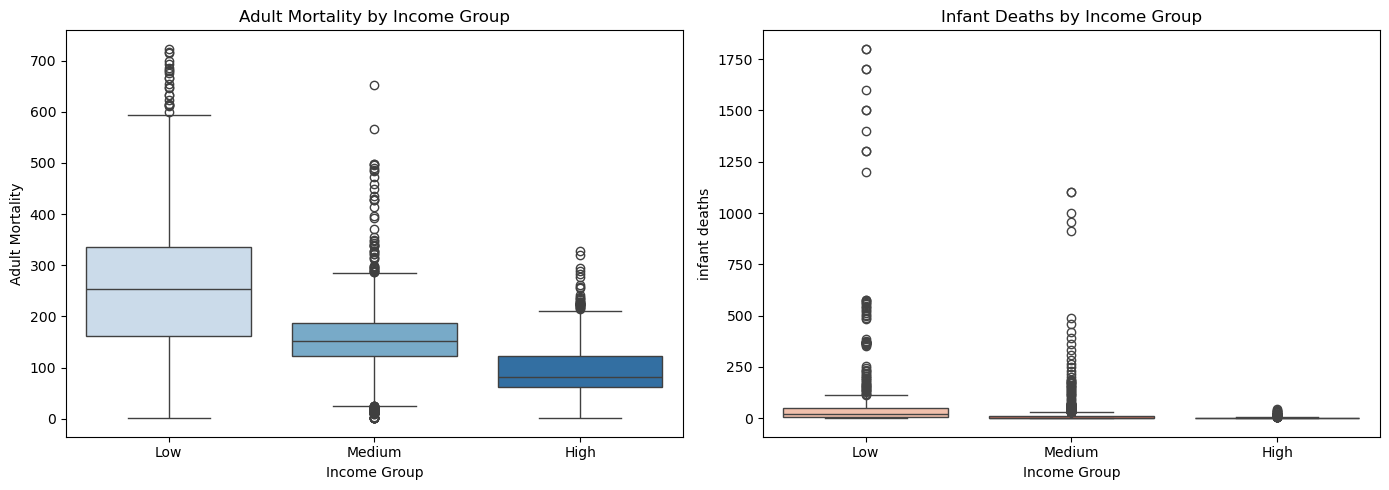

In [71]:
#How do leading causes of death (Adult Mortality vs Infant deaths) vary by income level?
# Create income groups
merged_df['Income Group'] = pd.qcut(merged_df['Income composition of resources'], 
                                  q=3, #creating 3 groups the low and medium and high
                                  labels=['Low', 'Medium', 'High'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5)) # 1 row, 2 columns, 14x5 inches

# Adult Mortality
sns.boxplot(
    data=merged_df,
    x='Income Group',
    y='Adult Mortality',
    ax=ax1,
    palette='Blues'
)
ax1.set_title('Adult Mortality by Income Group')

# Infant Deaths
sns.boxplot(
    data=merged_df,
    x='Income Group',
    y='infant deaths',
    ax=ax2,
    palette='Reds'
)
ax2.set_title('Infant Deaths by Income Group')

plt.tight_layout() # Adjust layout to prevent overlapping of different shapes 
plt.show() #show visualization

/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/521758303.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Status', y='thinness  1-19 years', data=df_box, palette='Set2')
/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/521758303.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Status', y='thinness 5-9 years', data=df_box, palette='Set2')


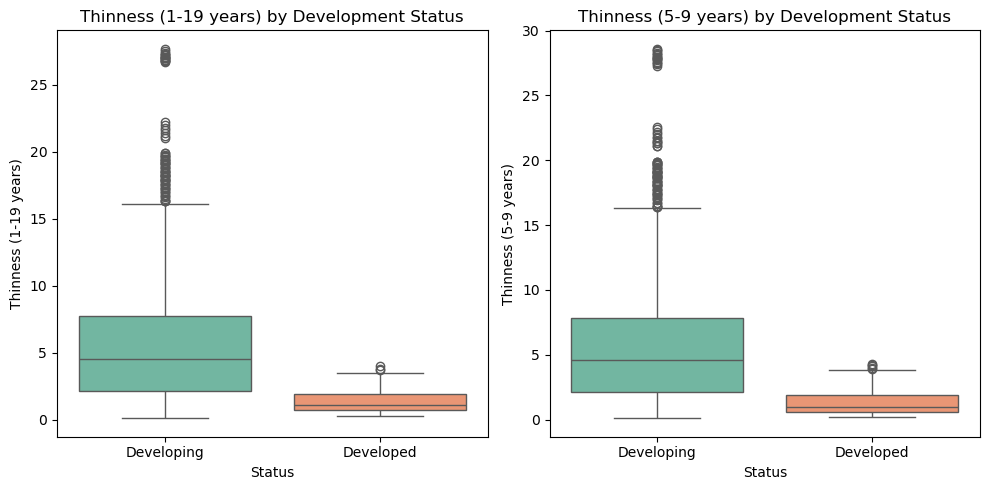

In [73]:

# visualize the prevalence of thinness in children across different Status and how these trends have changed over time

# Data Cleaning and Preparation
# Drop rows with missing values in the relevant columns for these plots
df_box = merged_df[['Status', 'thinness  1-19 years', 'thinness 5-9 years']].dropna()
df_line = merged_df[['Year', 'Status', 'thinness  1-19 years', 'thinness 5-9 years']].dropna()

#  Box Plots of Thinness by Status
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1) #(rows, columns,index)
sns.boxplot(x='Status', y='thinness  1-19 years', data=df_box, palette='Set2')
plt.title('Thinness (1-19 years) by Development Status')
plt.xlabel('Status')
plt.ylabel('Thinness (1-19 years)')

plt.subplot(1, 2, 2)
sns.boxplot(x='Status', y='thinness 5-9 years', data=df_box, palette='Set2')
plt.title('Thinness (5-9 years) by Development Status')
plt.xlabel('Status')
plt.ylabel('Thinness (5-9 years)')

plt.tight_layout() #prevent overlapping
plt.show() #show visualisation 



/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/2173529179.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adult_mortality_trends = df_mortality_pop_alcohol.groupby(['Year', 'Alcohol Level'])['Adult Mortality'].mean().reset_index()


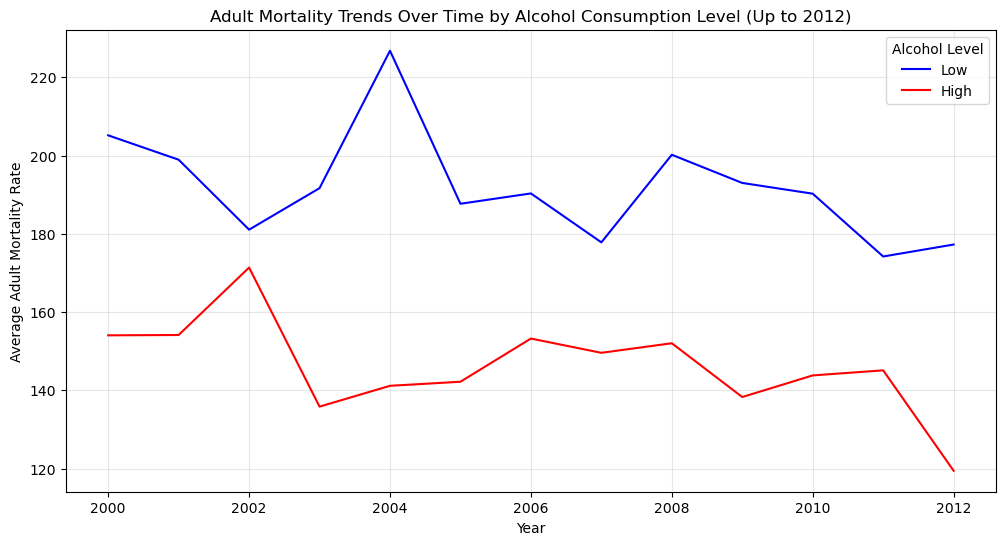

/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/2173529179.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  population_trends = df_mortality_pop_alcohol.groupby(['Year', 'Alcohol Level'])['Population'].mean().reset_index()


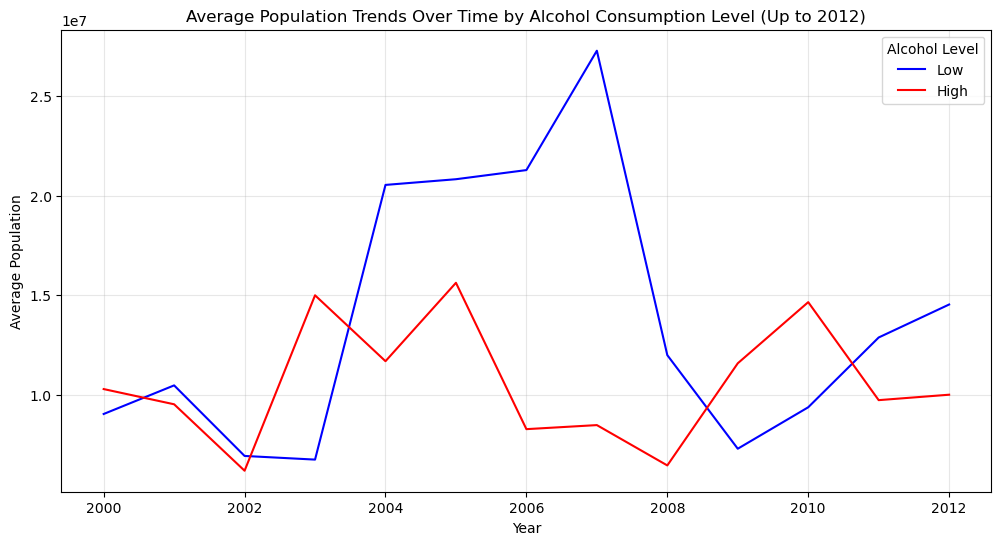

In [75]:

# 1. Data Cleaning: Remove rows with missing values and filter years up to 2012
df_mortality_pop_alcohol = merged_df[['Year', 'Adult Mortality', 'Population', 'Alcohol']].dropna()
df_mortality_pop_alcohol = df_mortality_pop_alcohol[df_mortality_pop_alcohol['Year'] <= 2012]

# 2. Create Categories for Alcohol Consumption ( Low and High)
# Defining bins to split into Low (0-5) and High (5+)
bins = [0, 5, df_mortality_pop_alcohol['Alcohol'].max() + 1]
labels = ['Low', 'High']
df_mortality_pop_alcohol['Alcohol Level'] = pd.cut(df_mortality_pop_alcohol['Alcohol'], bins=bins, labels=labels, right=False)

# 3. Analyze Adult Mortality Trends Over Time by Alcohol Level (Low and High)
adult_mortality_trends = df_mortality_pop_alcohol.groupby(['Year', 'Alcohol Level'])['Adult Mortality'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(x='Year', y='Adult Mortality', hue='Alcohol Level', data=adult_mortality_trends, palette={'Low': 'blue', 'High': 'red'})
plt.title('Adult Mortality Trends Over Time by Alcohol Consumption Level (Up to 2012)')
plt.xlabel('Year')
plt.ylabel('Average Adult Mortality Rate')
plt.legend(title='Alcohol Level')
plt.grid(True, alpha=0.3)
plt.show()

# 4. Analyze Population Trends Over Time by Alcohol Level ( Low and High)
population_trends = df_mortality_pop_alcohol.groupby(['Year', 'Alcohol Level'])['Population'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(x='Year', y='Population', hue='Alcohol Level', data=population_trends, palette={'Low': 'blue', 'High': 'red'})
plt.title('Average Population Trends Over Time by Alcohol Consumption Level (Up to 2012)')
plt.xlabel('Year')
plt.ylabel('Average Population')
plt.legend(title='Alcohol Level')
plt.grid(True, alpha=0.3)
plt.show()

In [77]:
# Clean column names by stripping whitespace
merged_df.columns = merged_df.columns.str.strip()

# Create bins for continuous variables
def create_bins(df, col, bins, labels):
    return pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)

/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/724985695.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=merged_df,
/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/724985695.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=merged_df,


Text(0, 0.5, 'Life Expectancy (years)')

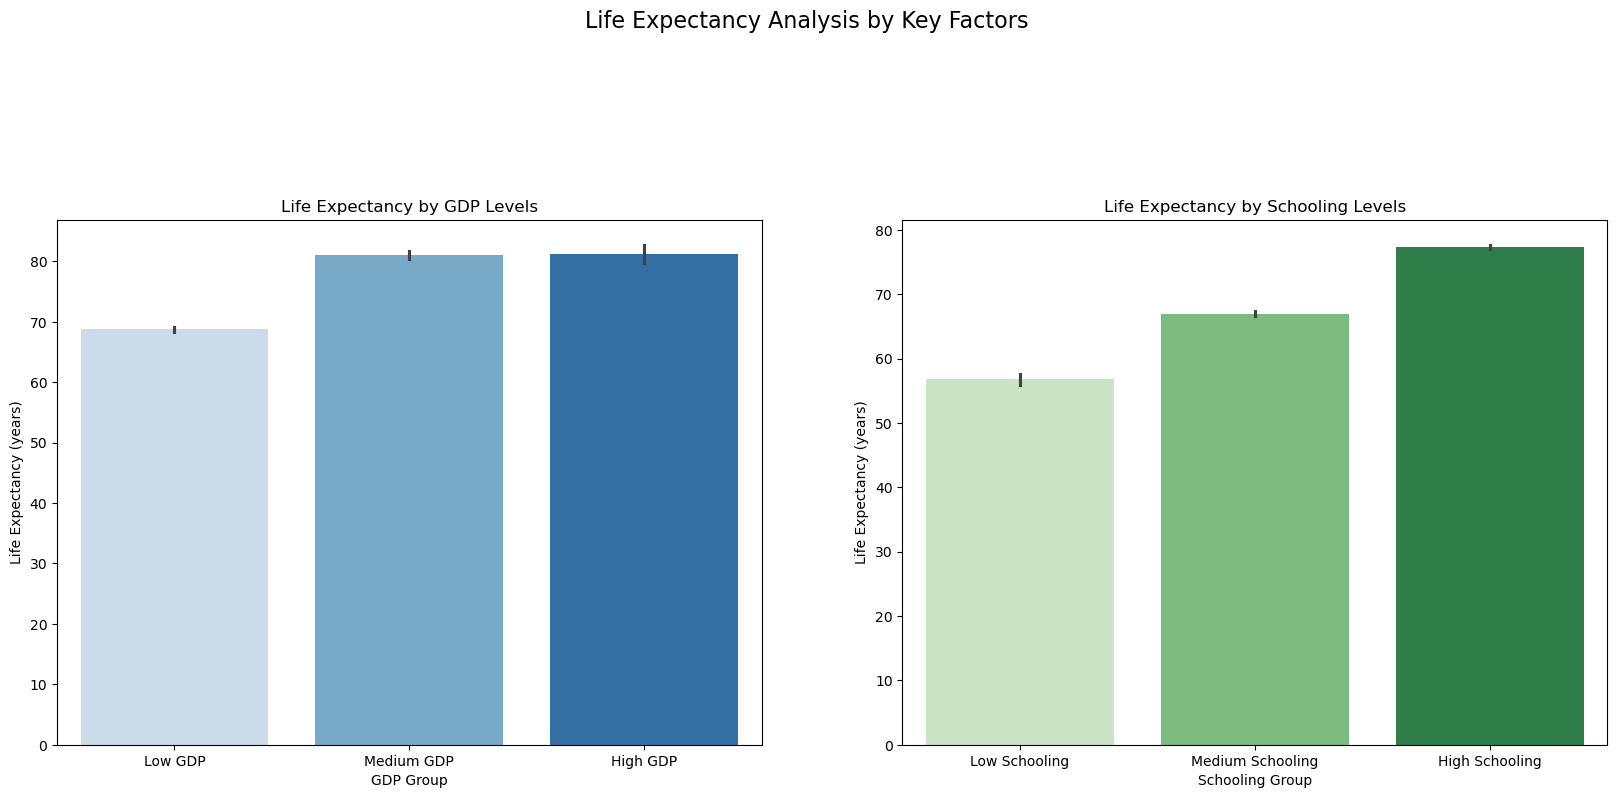

In [89]:

# Create 3 equal-sized bins for each variable
merged_df['GDP Group'] = create_bins(merged_df, 'GDP', 
                                   bins=3, 
                                   labels=['Low GDP', 'Medium GDP', 'High GDP'])
merged_df['Schooling Group'] = create_bins(merged_df, 'Schooling', 
                                         bins=3, 
                                         labels=['Low Schooling', 'Medium Schooling', 'High Schooling'])

# Set up the figure
plt.figure(figsize=(20, 15))
plt.suptitle('Life Expectancy Analysis by Key Factors', fontsize=16, y=1.02)

# 1. Life Expectancy vs GDP

plt.subplot(2, 2, 1)
sns.barplot(data=merged_df, 
           x='GDP Group', 
           y='Life expectancy',
           order=['Low GDP', 'Medium GDP', 'High GDP'],
           palette='Blues')
plt.title('Life Expectancy by GDP Levels')
plt.xlabel('GDP Group')
plt.ylabel('Life Expectancy (years)')

# 2. Life Expectancy vs Schooling

plt.subplot(2, 2, 2)
sns.barplot(data=merged_df, 
           x='Schooling Group', 
           y='Life expectancy',
           order=['Low Schooling', 'Medium Schooling', 'High Schooling'],
           palette='Greens')
plt.title('Life Expectancy by Schooling Levels')
plt.xlabel('Schooling Group')
plt.ylabel('Life Expectancy (years)')


/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/3666261813.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=merged_df,
/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/3666261813.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=merged_df,


Text(0, 0.5, 'Life Expectancy (years)')

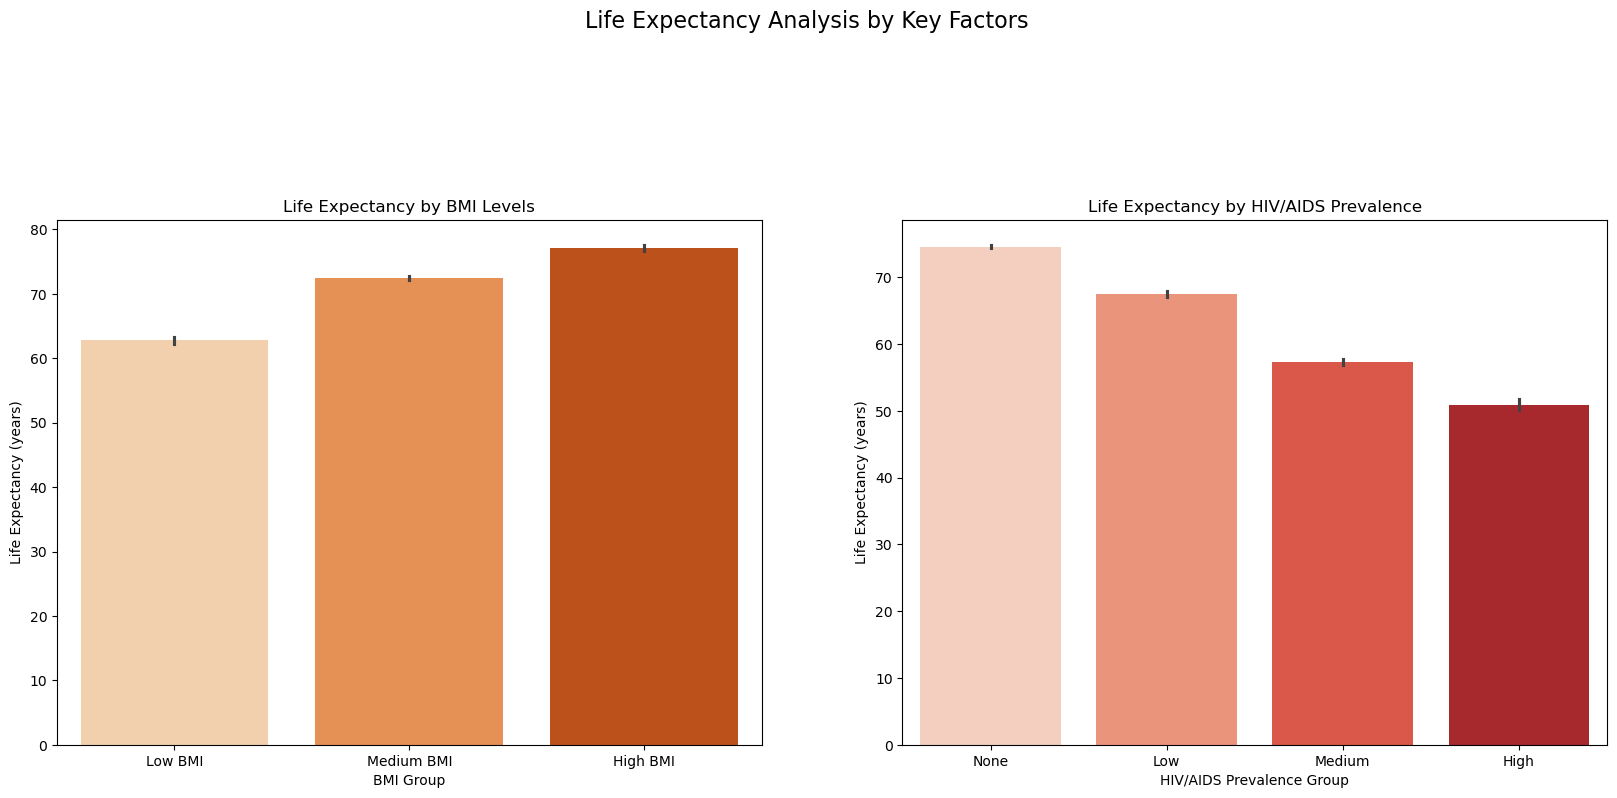

In [81]:
merged_df['BMI Group'] = create_bins(merged_df, 'BMI', 
                                   bins=3, 
                                   labels=['Low BMI', 'Medium BMI', 'High BMI'])
merged_df['HIV/AIDS Group'] = create_bins(merged_df, 'HIV/AIDS', 
                                        bins=[-1, 0.1, 1, 10, 100], 
                                        labels=['None', 'Low', 'Medium', 'High'])
# Set up the figure
plt.figure(figsize=(20, 15))
plt.suptitle('Life Expectancy Analysis by Key Factors', fontsize=16, y=1.02)

# 3. Life Expectancy vs BMI

plt.subplot(2, 2, 1)
sns.barplot(data=merged_df, 
           x='BMI Group', 
           y='Life expectancy',
           order=['Low BMI', 'Medium BMI', 'High BMI'],
           palette='Oranges')
plt.title('Life Expectancy by BMI Levels')
plt.xlabel('BMI Group')
plt.ylabel('Life Expectancy (years)')



# 4. Life Expectancy vs HIV/AIDS

plt.subplot(2, 2, 2)
sns.barplot(data=merged_df, 
           x='HIV/AIDS Group', 
           y='Life expectancy',
           order=['None', 'Low', 'Medium', 'High'],
           palette='Reds')
plt.title('Life Expectancy by HIV/AIDS Prevalence')
plt.xlabel('HIV/AIDS Prevalence Group')
plt.ylabel('Life Expectancy (years)')



/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/1930475851.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=merged_df,
/var/folders/kr/gcjn992x7kvdrlt3hc642tkc0000gn/T/ipykernel_5567/1930475851.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=merged_df,


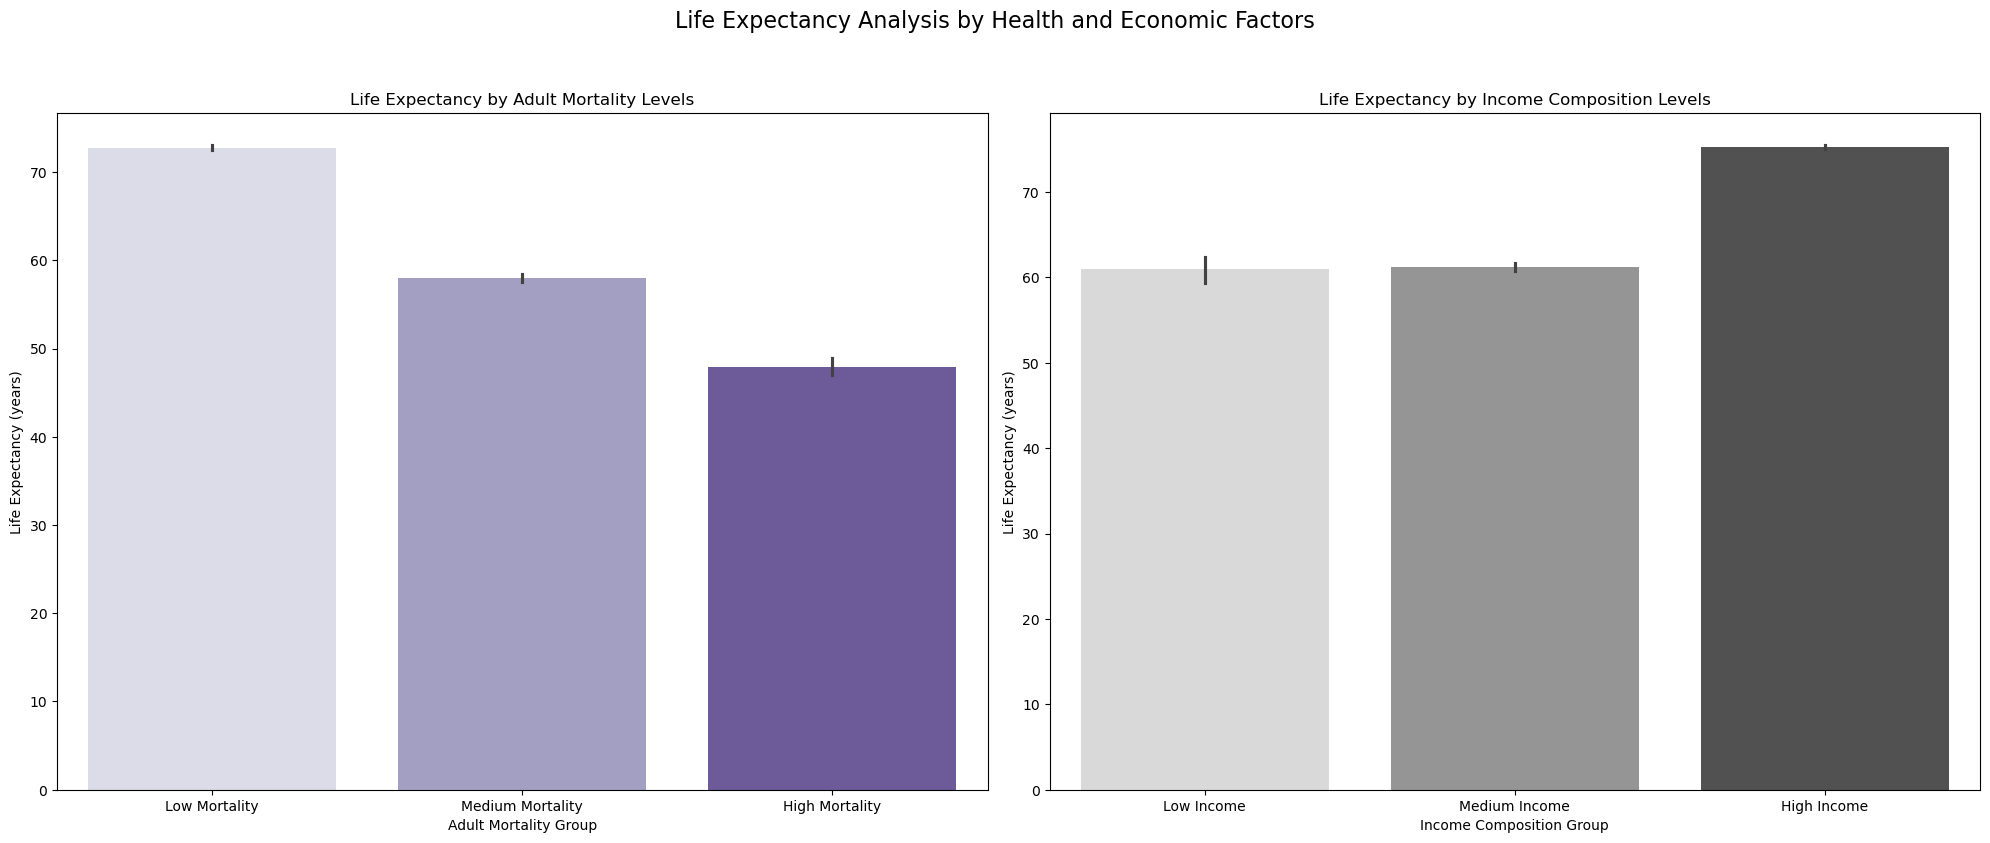

In [83]:
# Create groups for Adult Mortality and Income Composition
merged_df['Adult Mortality Group'] = create_bins(merged_df, 'Adult Mortality', 
                                               bins=3, 
                                               labels=['Low Mortality', 'Medium Mortality', 'High Mortality'])
merged_df['Income Group'] = create_bins(merged_df, 'Income composition of resources', 
                                      bins=3, 
                                      labels=['Low Income', 'Medium Income', 'High Income'])

# Set up the figure
plt.figure(figsize=(20, 15))
plt.suptitle('Life Expectancy Analysis by Health and Economic Factors', fontsize=16, y=1.02)

# 5. Life Expectancy vs Adult Mortality

plt.subplot(2, 2, 1)
sns.barplot(data=merged_df, 
           x='Adult Mortality Group', 
           y='Life expectancy',
           order=['Low Mortality', 'Medium Mortality', 'High Mortality'],
           palette='Purples')
plt.title('Life Expectancy by Adult Mortality Levels')
plt.xlabel('Adult Mortality Group')
plt.ylabel('Life Expectancy (years)')

# 6. Life Expectancy vs Income Composition

plt.subplot(2, 2, 2)
sns.barplot(data=merged_df, 
           x='Income Group', 
           y='Life expectancy',
           order=['Low Income', 'Medium Income', 'High Income'],
           palette='Greys')
plt.title('Life Expectancy by Income Composition Levels')
plt.xlabel('Income Composition Group')
plt.ylabel('Life Expectancy (years)')

plt.tight_layout()
plt.show()


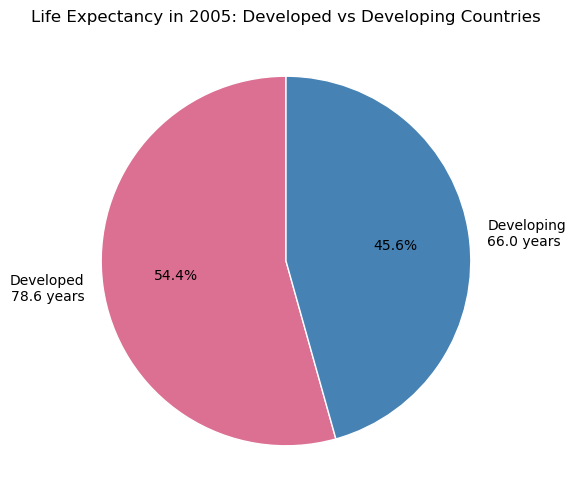


2005 Life Expectancy Comparison:
Developed Countries: 78.6 years
Developing Countries: 66.0 years
Difference: 12.6 years
Gap Percentage: 19.1%


In [85]:

# Clean 'Status' and filter for 2005 data
merged_df['Status'] = merged_df['Status'].str.strip()
df_2005 = merged_df[merged_df['Year'] == 2005].copy()

# Calculate average life expectancy
avg_life = df_2005.groupby('Status')['Life expectancy'].mean()

# Create and display the pie chart

plt.figure(figsize=(8, 6))
labels = [f'{status}\n{age:.1f} years' if pd.notna(age) else f'{status}\nN/A' for status, age in avg_life.items()]
colors = ['palevioletred', 'steelblue'] 
plt.pie(avg_life, labels=labels, colors=colors,autopct='%1.1f%%', startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1})
plt.title('Life Expectancy in 2005: Developed vs Developing Countries')
plt.show()


# Print 2005 Life Expectancy Comparison
print("\n2005 Life Expectancy Comparison:")
developed_life_exp = avg_life['Developed']
developing_life_exp = avg_life['Developing']
print(f"Developed Countries: {developed_life_exp:.1f} years")
print(f"Developing Countries: {developing_life_exp:.1f} years")
print(f"Difference: {developed_life_exp - developing_life_exp:.1f} years")
print(f"Gap Percentage: {(developed_life_exp / developing_life_exp - 1) * 100:.1f}%")


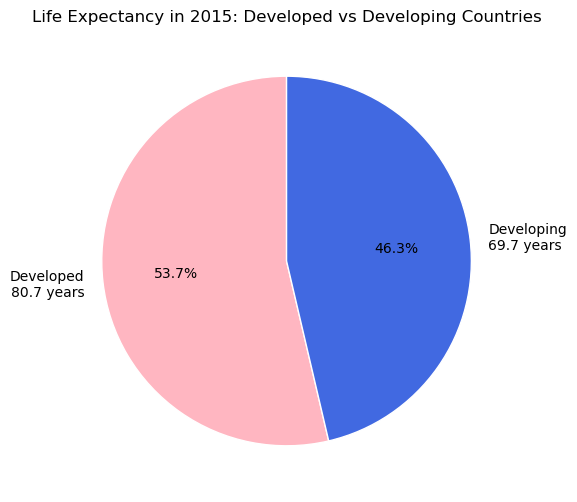


2015 Life Expectancy Comparison:
Developed Countries: 80.7 years
Developing Countries: 69.7 years
Difference: 11.0 years
Gap Percentage: 15.8%


In [87]:
# Clean 'Status' and filter for 2005 data
merged_df['Status'] = merged_df['Status'].str.strip()
df_2015 = merged_df[merged_df['Year'] == 2015].copy()

# Calculate average life expectancy
avg_life = df_2015.groupby('Status')['Life expectancy'].mean()

# Create and display the pie chart

plt.figure(figsize=(8, 6))
labels = [f'{status}\n{age:.1f} years' if pd.notna(age) else f'{status}\nN/A' for status, age in avg_life.items()]
colors = ['lightpink', 'royalblue'] 
plt.pie(avg_life, labels=labels, colors=colors,autopct='%1.1f%%', startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1})
plt.title('Life Expectancy in 2015: Developed vs Developing Countries')
plt.show()


# Print 2005 Life Expectancy Comparison
print("\n2015 Life Expectancy Comparison:")
developed_life_exp = avg_life['Developed']
developing_life_exp = avg_life['Developing']
print(f"Developed Countries: {developed_life_exp:.1f} years")
print(f"Developing Countries: {developing_life_exp:.1f} years")
print(f"Difference: {developed_life_exp - developing_life_exp:.1f} years")
print(f"Gap Percentage: {(developed_life_exp / developing_life_exp - 1) * 100:.1f}%")